# Tensor Network Surface Code Decoding & Reduction
### A runnable nine-qubit study for Track 3

**Question:** Can a small tensor network choose a good recovery, and what changes
when we compress its intermediate tensors?

A physical error changes one or more data qubits. Stabilizer measurements give us
an eight-bit **syndrome**: a set of warning lights, not a list of the errors.
Different errors can light up the same checks. We add the probabilities of all
errors that have the same logical effect, then choose the most likely effect.

**Scope.** A rotated distance-3 surface code uses nine **data** qubits to protect
one logical qubit. This is a **code-capacity** experiment: independent Pauli errors
on the data, perfect syndrome extraction, and no measurement or gate noise.
Ancillas for a physical extraction circuit are not included. This is not a full
fault-tolerant hardware simulation or a threshold study.

**Statement availability.** The supplied attachment contains the detailed
implementation request; the separately referenced IBM Qiskit Fall Fest 2026
problem statement was not attached. This notebook follows that request. Organizer
terminology and any additional track rubric remain unverified.

We interpret the described 10:1 bias as the mutually exclusive channel
\[
 (P(I),P(X),P(Y),P(Z))=(1-p,10p/11,0,p/11).
\]
This is **not a flagged-erasure model**. Drawing X and Z independently would produce
Y errors and implement a different channel. We also provide depolarizing and equal-X/Z
channels. No cloud service, hardware account, or pretrained decoder is used.

In [1]:
from pathlib import Path
import json
import os
import sys
import importlib.metadata
import numpy as np
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "surface_tn").is_dir():
    raise RuntimeError("Run this notebook with the project root as its working directory.")
from surface_tn import SurfaceCode, NoiseModel, Decoder, Settings, pauli, pauli_label
from surface_tn.code import CLASS_NAMES
from surface_tn.reference import validate_all_syndromes, enumerated_weights
from surface_tn.experiments import run_experiments
from surface_tn.plots import (save, patch_figure, posterior_figure, failure_figure,
                              runtime_figure, tradeoff_figure)

RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 20261031
TRIALS = int(os.environ.get("TN_TRIALS", "10000"))
BENCHMARK_TRIALS = int(os.environ.get("TN_BENCHMARK_TRIALS", "96"))
P_VALUES = (.01, .03, .06, .10, .15)
print(json.dumps({"seed": SEED, "trials_per_p": TRIALS, "physical_probabilities": P_VALUES,
                  "uncached_timing_trials_per_method_per_p": BENCHMARK_TRIALS,
                  "python": sys.version.split()[0],
                  "versions": {p: importlib.metadata.version(p) for p in
                               ("numpy", "scipy", "qiskit", "matplotlib", "nbformat", "nbclient", "ipykernel", "pytest")}}, indent=2))

{
  "seed": 20261031,
  "trials_per_p": 10000,
  "physical_probabilities": [
    0.01,
    0.03,
    0.06,
    0.1,
    0.15
  ],
  "uncached_timing_trials_per_method_per_p": 96,
  "python": "3.11.9",
  "versions": {
    "numpy": "2.4.6",
    "scipy": "1.17.1",
    "qiskit": "2.6.1",
    "matplotlib": "3.11.2",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.4.0",
    "pytest": "9.2.0"
  }
}


## 1. A code we can check completely

Qubit $q=3r+c$ sits at column $c$, row $r$, with row zero at the top.
Our binary representation is $(x_0,\ldots,x_8\mid z_0,\ldots,z_8)$:
I is $(0,0)$, X is $(1,0)$, Z is $(0,1)$, and Y is $(1,1)$.
Multiplication is XOR when we ignore an irrelevant global phase.

Two Paulis commute exactly when $x\cdot z'+z\cdot x'=0\pmod2$.
The syndrome bit is one when the error anticommutes with that stabilizer.
Strings printed below use Qiskit's order **q8 ... q0**; qubit zero is on the right.
The displayed check supports use ordinary ascending qubit numbers.

The eight independent commuting checks leave $2^{9-8}=2$ code states: one logical
qubit. We choose $X_L=X_0X_3X_6$ and $Z_L=Z_0Z_1Z_2$. They cross once and anticommute.
Boundary labels name the string type that can end there; no rough/smooth naming
convention is needed.

In [2]:
code = SurfaceCode()
algebra_report = code.validate(use_qiskit=True)
lines = ["| Check | Type | Data-qubit support | Pauli string (q8 ... q0) |",
         "|---|---|---|---|"]
for check, operator in zip(code.checks, code.stabilizers):
    lines.append(f"| {check['name']} | {check['kind']} | {check['support']} | `{pauli_label(operator)}` |")
display(Markdown("\n".join(lines)))
print("Logical X:", pauli_label(code.logical_x), "Logical Z:", pauli_label(code.logical_z))
print(json.dumps(algebra_report, indent=2))
(RESULTS / "code_validation.json").write_text(json.dumps(algebra_report, indent=2), encoding="utf-8")

| Check | Type | Data-qubit support | Pauli string (q8 ... q0) |
|---|---|---|---|
| X0 | X | (1, 2) | `IIIIIIXXI` |
| X1 | X | (0, 1, 3, 4) | `IIIIXXIXX` |
| X2 | X | (4, 5, 7, 8) | `XXIXXIIII` |
| X3 | X | (6, 7) | `IXXIIIIII` |
| Z0 | Z | (0, 3) | `IIIIIZIIZ` |
| Z1 | Z | (1, 2, 4, 5) | `IIIZZIZZI` |
| Z2 | Z | (3, 4, 6, 7) | `IZZIZZIII` |
| Z3 | Z | (5, 8) | `ZIIZIIIII` |

Logical X: IIXIIXIIX Logical Z: IIIIIIZZZ
{
  "data_qubits": 9,
  "stabilizer_rank": 8,
  "logical_qubits": 1,
  "distance": 3,
  "paulis_checked_for_distance": 2619,
  "qiskit_operator_pairs_checked": 121
}


165

Validation checks all commutators, rank eight, logical commutators and
anticommutators, and that the logical operators are outside the stabilizer group.
It exhausts every Pauli of weights one, two, and three: none of weights one or two
acts as an undetectable logical error, and some of weight three do. Therefore the
distance is **exactly three**. Qiskit's `Pauli` independently checks commutation,
composition, and string ordering; it is used for algebra validation, not decoding.

## 2. One worked recovery

We first generate a syndrome and hand **only that syndrome** to the decoder.
The error is revealed afterwards for explanation and scoring. The reference
recovery $R_s$ is a deterministic solution of the binary linear equation $HR_s=s$,
with free variables set to zero. It is only a starting point; it need not be the
best physical correction.

{
  "injected_error_q8_to_q0": "IIIIXIIII",
  "syndrome_check_order": [
    "X0",
    "X1",
    "X2",
    "X3",
    "Z0",
    "Z1",
    "Z2",
    "Z3"
  ],
  "syndrome": [
    0,
    0,
    0,
    0,
    0,
    1,
    1,
    0
  ],
  "reference_recovery": "IIIIIXIXX",
  "raw_weights_IXYZ": [
    0.038736606685722194,
    0.011896739302640137,
    2.3321571513354873e-08,
    7.51418077538311e-08
  ],
  "posterior_IXYZ": [
    0.765039927762406,
    0.23495812760632628,
    4.6059618826806276e-07,
    1.4840350793327573e-06
  ],
  "selected_class": "I",
  "physical_recovery": "IIIIIXIXX",
  "success": true,
  "residual_class": "I",
  "residual": "IIIIXXIXX"
}


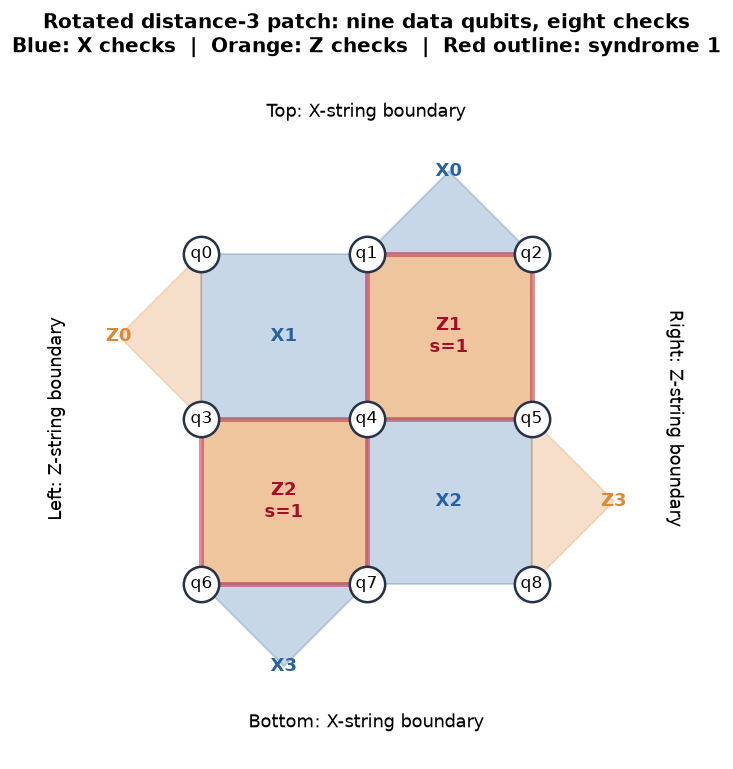

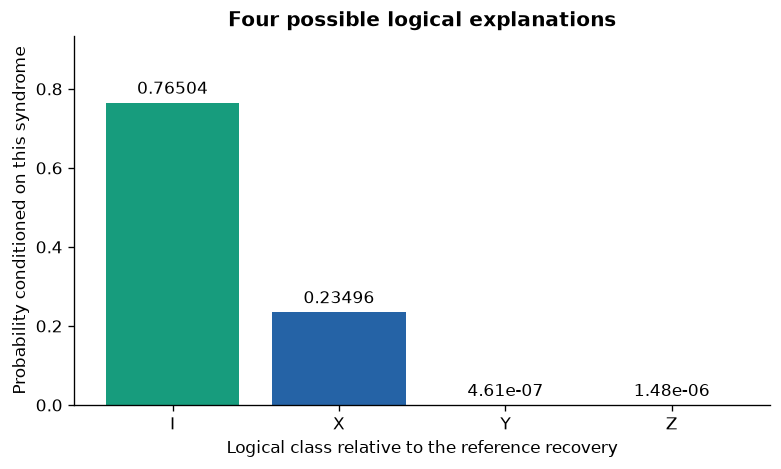

In [3]:
example_noise = NoiseModel.biased(.08)
example_error = pauli(x=(4,))
example_syndrome = code.syndrome(example_error)
example_decoder = Decoder(code, example_noise)
example = example_decoder.decode(example_syndrome)
# The decoder call above has no access to example_error.
evaluation = code.evaluate(example_error, example.correction)
example_record = {
    "injected_error_q8_to_q0": pauli_label(example_error),
    "syndrome_check_order": [c["name"] for c in code.checks],
    "syndrome": example_syndrome.tolist(),
    "reference_recovery": pauli_label(example.reference),
    "raw_weights_IXYZ": example.weights.tolist(),
    "posterior_IXYZ": example.posterior.tolist(),
    "selected_class": CLASS_NAMES[example.selected_class],
    "physical_recovery": pauli_label(example.correction), **evaluation,
}
print(json.dumps(example_record, indent=2))
(RESULTS / "worked_example.json").write_text(json.dumps(example_record, indent=2), encoding="utf-8")
fig = save(patch_figure(code, example_syndrome), FIGURES / "patch_and_syndrome.png")
display(fig)
plt.close(fig)
fig = save(posterior_figure(example), FIGURES / "class_posterior.png")
display(fig)
plt.close(fig)

The patch figure is generated from the same geometry that defines the checks and
the tensor network. Red check outlines show the nonzero syndrome bits.
The bar chart shows **logical-class probabilities**, not single-qubit probabilities
or quantum amplitudes. Logical I means "the same logical effect as the reference
recovery," not "nothing happened."

The selected class is combined with the reference to form the physical correction
$R=R_sL$. We test the residual $RE$. Clearing the syndrome is necessary but not
sufficient: a zero-syndrome logical X, Y, or Z still corrupts the protected qubit.
Success means $RE$ belongs to the stabilizer group, up to global phase.

## 3. What the tensor network actually sums

Every error with syndrome $s$ belongs to exactly one coset $R_sL\mathcal S$,
where $L\in\{I,X_L,Y_L,Z_L\}$. Its total probability is
\[
 w_L(s)=\sum_{g\in\mathcal S}P(R_sLg)
       =\sum_{a_0,\ldots,a_7\in\{0,1\}}
          \prod_{q=0}^{8}p_q\!\left[(R_sL)_q\prod_j(S_j)_q^{a_j}\right].
\]
Here $a_j$ decides whether to include stabilizer generator $j$. The sum has 256
terms, but the decoder evaluates it by contracting **local tensors on a 3 by 3
grid**, not by enumerating those terms.

**One tensor per data qubit.** Its four neighboring face bits are
$a_{UL},a_{UR},a_{LL},a_{LR}$. A missing face is fixed to zero. Its legs carry pairs:

| Leg | Face bits carried | Maximum dimension |
|---|---|---|
| left | $(a_{UL},a_{LL})$ | 4 |
| right | $(a_{UR},a_{LR})$ | 4 |
| up | $(a_{UL},a_{UR})$ | 4 |
| down | $(a_{LL},a_{LR})$ | 4 |

The tensor entry is zero unless duplicated corner bits agree. If they agree,
it equals the local probability $p_q$ of the resulting I, X, Y, or Z.
These are copy constraints fused with a probability tensor. Joining adjacent legs
copies each face's generator bit to its participating qubits. An outer leg is
summed against an all-ones vector; the boundary generators still connect their
two data sites. Each globally consistent assignment contributes exactly once.
This construction also works when the local Y probability is zero.

We make four explicit contractions, in order **[I, X, Y, Z]**. Their sum is $P(s)$.
When it is positive, $P(L\mid s)=w_L(s)/\sum_K w_K(s)$. If it is zero, the decoder
returns an explicit impossible-syndrome status and no posterior or correction.

**Exact contraction.** We sweep rows, maintaining the full dense boundary over
the open vertical legs. There are only three sites across, so it is small.
There is no SVD or truncation in this path. Reflecting the grid exchanges the
row and column contraction directions.

In [4]:
grid = example_decoder.network.build(example.reference, example_noise.probabilities)
print("Exact local tensor shapes (left, right, up, down), after outer-edge sums:")
for row in grid:
    print([tensor.shape for tensor in row])
print("Exact class-contraction boundary sizes:",
      [item["peak_boundary_entries"] for item in example.diagnostics["attempts"][0]["class_diagnostics"]])

Exact local tensor shapes (left, right, up, down), after outer-edge sums:
[(1, 2, 1, 4), (2, 4, 1, 4), (4, 1, 1, 2)]
[(1, 4, 4, 2), (4, 4, 4, 4), (4, 1, 2, 4)]
[(1, 4, 2, 1), (4, 2, 4, 1), (2, 1, 4, 1)]
Exact class-contraction boundary sizes: [32, 32, 32, 32]


## 4. Independent exact-reference validation

For this patch we can also enumerate the stabilizer group independently. That
transparent calculation lives in `surface_tn/reference.py` and is never imported
by the decoder. We compare raw weights as well as normalized posteriors, for all
256 syndromes of a full-support depolarizing channel. We use absolute tolerance
$10^{-15}$ and relative tolerance $2\times10^{-11}$; small raw weights alone must
not hide posterior errors. The sum of all class weights over all syndromes must
also equal one. Tests additionally cover an asymmetric full-support channel and
the requested zero-Y biased channel.

In [5]:
validation_noise = NoiseModel.depolarizing(.13)
validation = validate_all_syndromes(code, Decoder(code, validation_noise), validation_noise)
print(json.dumps(validation, indent=2))
(RESULTS / "exact_reference_validation.json").write_text(json.dumps(validation, indent=2), encoding="utf-8")
impossible = Decoder(code, NoiseModel.biased(0)).decode(code.syndrome(pauli(x=(4,))))
print("Zero-noise model, nonzero syndrome:", impossible.diagnostics["status"],
      "posterior =", impossible.posterior)

{
  "syndromes_checked": 256,
  "supported_syndromes": 256,
  "max_absolute_raw_error": 1.1102230246251565e-16,
  "max_absolute_posterior_error": 3.3306690738754696e-16,
  "total_probability_mass": 0.9999999999999968,
  "rtol": 2e-11,
  "atol": 1e-15
}
Zero-noise model, nonzero syndrome: impossible_syndrome posterior = None


## 5. Compression: keep the useful correlations

An MPS represents the boundary as a chain of small tensors. The internal **bond
dimension** counts how much information one part of the boundary shares with the
next. Absorbing a row joins its tensors to the boundary and grows those bonds:
\[
 A'_{(a\ell),d,(br)}=\sum_u A_{a,u,b}\,T_{\ell,r,u,d}.
\]
We right-canonicalize with QR, then sweep left to right using singular-value
decomposition (SVD). This makes each discarded singular value meaningful for the
current boundary. We compress after the first two rows; after the last row there
is only a scalar to read out.

Two controls have different jobs:

* **Tolerance $\tau$:** choose the smallest rank $k\ge1$ with
  $\sum_{i>k}\sigma_i^2/\sum_i\sigma_i^2\le\tau$. Setting it to zero keeps all
  singular values unless the bond cap forces a truncation.
* **Maximum bond dimension $\chi$:** impose $k\le\chi$, even if that exceeds the
  tolerance budget. We record the actual retained rank, full singular spectrum,
  discarded squared norm, and its relative value at every compressed bond.

**Adaptive policy:** start at $\chi=1$ and double it when the largest relative
discarded squared norm across any bond and any of the four classes exceeds
$10^{-8}$. Stop when it passes, or at $\chi=8$. This policy sees neither the true
error nor an exact-reference answer. Every retry counts toward runtime.
The cap and target can be configured separately. This diagnostic is **not a bound
on logical failure probability**, nor on relative error in rare logical classes.

If a contraction produces a significantly negative weight (below $-10^{-12}$
times the sum of absolute weights), nonfinite values, or nonpositive normalization,
the decoder explicitly records the issue and increases the bond cap. At the
configured safety cap it recomputes with exact contraction, reporting that fallback.
This also distinguishes an impossible syndrome from an approximate zero. Thus
"fixed chi" denotes a requested cap; a numerical safety retry is always disclosed.
Tiny roundoff negatives alone may be set to zero for normalization; raw weights
remain available. In ordinary successful adaptive runs there is no exact fallback.

In [6]:
adaptive_example = Decoder(code, example_noise, Settings("adaptive", chi=1, max_chi=8)).decode(example_syndrome)
adaptation_rows = []
for attempt in adaptive_example.diagnostics["attempts"]:
    ranks = sorted({b["retained"] for c in attempt["class_diagnostics"] for b in c["bonds"]})
    adaptation_rows.append({"requested_chi": attempt["chi"], "retained_ranks": ranks,
                            "maximum_relative_discarded_squared": attempt["max_relative_discarded_squared"],
                            "raw_weights_IXYZ": attempt["raw_weights"],
                            "numerical_issue": attempt["numerical_issue"]})
print(json.dumps(adaptation_rows, indent=2))
print("Exact posterior:", example.posterior)
print("Adaptive posterior:", adaptive_example.posterior)
print("Selected class changed:", adaptive_example.selected_class != example.selected_class)
(RESULTS / "adaptive_example.json").write_text(json.dumps(adaptive_example.diagnostics, indent=2), encoding="utf-8")

[
  {
    "requested_chi": 1,
    "retained_ranks": [
      1
    ],
    "maximum_relative_discarded_squared": 0.49998437768508547,
    "raw_weights_IXYZ": [
      0.03779768716824093,
      0.011803849508719958,
      0.0,
      3.7110003265371284e-08
    ],
    "numerical_issue": null
  },
  {
    "requested_chi": 2,
    "retained_ranks": [
      2
    ],
    "maximum_relative_discarded_squared": 9.517938992797385e-13,
    "raw_weights_IXYZ": [
      0.038736606685722194,
      0.01189673930264013,
      2.332157151335496e-08,
      3.758020772124915e-08
    ],
    "numerical_issue": null
  }
]
Exact posterior: [7.65039928e-01 2.34958128e-01 4.60596188e-07 1.48403508e-06]
Adaptive posterior: [7.65040495e-01 2.34958302e-01 4.60596530e-07 7.42201839e-07]
Selected class changed: False


14366

## 6. Run the tests, then a small smoke experiment

The tests include code algebra and distance, Qiskit cross-checks, reference
recoveries for every syndrome, all single-qubit X/Y/Z errors at low depolarizing
noise, errors differing by stabilizers, a zero-syndrome logical failure, exact
versus untruncated MPS weights, adaptive stopping, numerical refinement,
impossible syndromes, reproducibility, and uncertainty calculations.

In [7]:
import subprocess
test_run = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=ROOT,
                          capture_output=True, text=True)
print(test_run.stdout)
if test_run.stderr:
    print(test_run.stderr)
(RESULTS / "test_results.txt").write_text(test_run.stdout + test_run.stderr, encoding="utf-8")
assert test_run.returncode == 0, "Correctness tests failed; do not continue to experiments."
smoke = run_experiments(RESULTS / "smoke", p_values=(.10,), trials=64,
                        benchmark_trials=8, seed=SEED)
print(f"Smoke experiment completed in {smoke['total_runtime_s']:.2f} s")

.....................                                                    [100%]
21 passed in 11.82s



p=0.100 exact              fail=7/64 (0.1094; 95% CI 0.0540-0.2090) median=0.975 ms


p=0.100 chi1               fail=13/64 (0.2031; 95% CI 0.1227-0.3171) median=4.258 ms


p=0.100 chi2               fail=7/64 (0.1094; 95% CI 0.0540-0.2090) median=3.749 ms


p=0.100 chi4               fail=7/64 (0.1094; 95% CI 0.0540-0.2090) median=4.520 ms


p=0.100 chi8               fail=7/64 (0.1094; 95% CI 0.0540-0.2090) median=4.571 ms


p=0.100 adaptive           fail=7/64 (0.1094; 95% CI 0.0540-0.2090) median=8.190 ms


p=0.100 chi2_column        fail=7/64 (0.1094; 95% CI 0.0540-0.2090) median=3.724 ms


p=0.100 equal_XZ_decoder   fail=7/64 (0.1094; 95% CI 0.0540-0.2090) median=0.994 ms


Smoke experiment completed in 9.78 s


## 7. Paired experiments with honest timing

We run five physical probabilities under the required 10:1 channel, with the
printed trial count at each probability. Every decoder at a given $p$ sees the
**same physical errors**. We compare exact contraction; requested fixed
$\chi=1,2,4,8$; adaptive compression; column contraction at $\chi=2$; and an exact
decoder that incorrectly assumes equal X/Z probabilities at the same $p$.

For statistics, we contract all 256 syndromes once per decoder and then reuse those
results. This cache is in the experiment code, not the decoder. For timing we
separately call the **uncached decoder** on the same randomly selected trial
syndromes, after three warmups, randomizing method order within each timing trial.
Reported time includes reference recovery, tensor construction, all contractions,
SVDs/retries, and correction selection. Reusable geometry construction and
Python import startup are excluded. Timing varies by CPU and concurrent load.

We report marginal **95% Wilson intervals** for logical failure/recovery and each
residual class. For paired differences, a conservative 95% interval combines
exact intervals for the two discordant outcomes (first decoder alone fails, or
second decoder alone fails). Each uses a 97.5% Clopper-Pearson interval; the
Bonferroni bound gives at least 95% coverage for their difference. We also save
4,000 paired multinomial bootstrap replicates and exact McNemar tests. The
bootstrap interval can collapse to zero when no discordance is observed, so it
is not evidence of equality; the conservative interval stays nonzero. These
intervals are not simultaneous bands across the entire experiment or evidence
of a threshold.

This patch is small enough to also compute the **population failure probability**:
$1-\sum_s w^{\rm actual}_{\hat L(s)}(s)$. These exact actual-channel weights are used
only by evaluation, after the decoder has selected its recovery. This removes
sampling uncertainty when comparing policies for this particular nine-qubit model.

In [8]:
report = run_experiments(RESULTS / "main", p_values=P_VALUES, trials=TRIALS,
                         benchmark_trials=BENCHMARK_TRIALS, seed=SEED)
print(f"Main experiment wall time: {report['total_runtime_s']:.2f} s")

p=0.010 exact              fail=12/10000 (0.0012; 95% CI 0.0007-0.0021) median=0.991 ms


p=0.010 chi1               fail=193/10000 (0.0193; 95% CI 0.0168-0.0222) median=3.971 ms


p=0.010 chi2               fail=12/10000 (0.0012; 95% CI 0.0007-0.0021) median=4.076 ms


p=0.010 chi4               fail=12/10000 (0.0012; 95% CI 0.0007-0.0021) median=3.958 ms


p=0.010 chi8               fail=12/10000 (0.0012; 95% CI 0.0007-0.0021) median=4.212 ms


p=0.010 adaptive           fail=12/10000 (0.0012; 95% CI 0.0007-0.0021) median=7.689 ms


... (31 outputs left out)

p=0.150 adaptive           fail=1937/10000 (0.1937; 95% CI 0.1861-0.2016) median=7.620 ms


p=0.150 chi2_column        fail=1937/10000 (0.1937; 95% CI 0.1861-0.2016) median=3.788 ms


p=0.150 equal_XZ_decoder   fail=1937/10000 (0.1937; 95% CI 0.1861-0.2016) median=1.011 ms


Main experiment wall time: 68.42 s


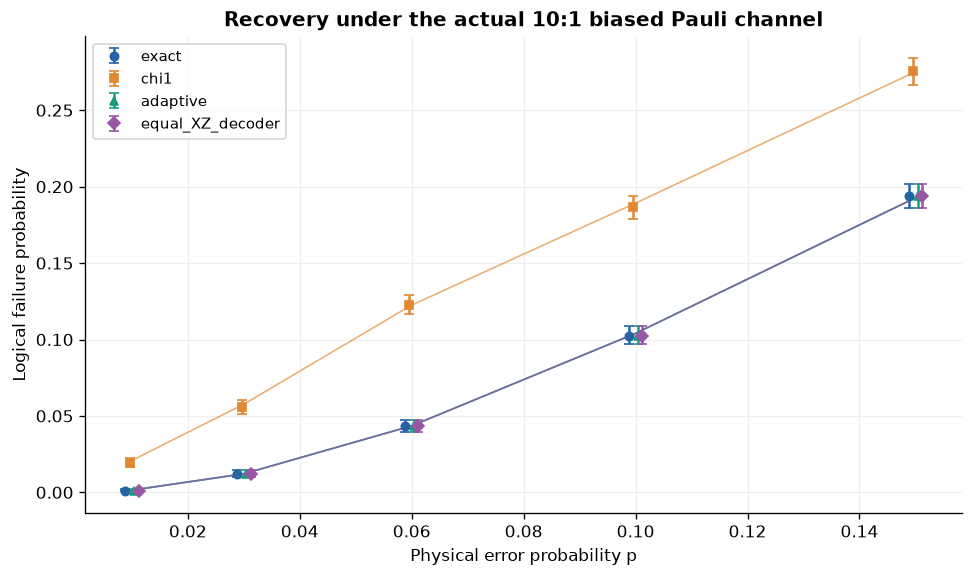

In [9]:
fig = save(failure_figure(report), FIGURES / "logical_failure_vs_p.png")
display(fig)
plt.close(fig)

**Why this graph matters:** the vertical axis is the chance of corrupting the
protected logical qubit after recovery. Error bars show sampling uncertainty;
thin lines show the population probabilities from summing all syndromes. Markers
are shifted slightly sideways so overlapping intervals remain visible. A lower
curve is better recovery at that physical error rate. A matched noise assumption
need not improve decisions for every small code or every parameter range; we
report what this experiment actually finds.

At **p=0.10**:

| Decoder | Failure count | Failure estimate [95% CI] | Population failure | Median / p95 ms | Residual I / X / Y / Z counts |
|---|---:|---|---:|---:|---|
| exact | 1026/10000 | 0.1026 [0.0968, 0.1087] | 0.104007 | 0.979 / 1.820 | [8974, 1018, 0, 8] |
| chi1 | 1864/10000 | 0.1864 [0.1789, 0.1942] | 0.189234 | 3.508 / 5.305 | [8136, 1774, 13, 77] |
| chi2 | 1026/10000 | 0.1026 [0.0968, 0.1087] | 0.104007 | 3.690 / 5.976 | [8974, 1018, 0, 8] |
| chi4 | 1026/10000 | 0.1026 [0.0968, 0.1087] | 0.104007 | 3.845 / 5.681 | [8974, 1018, 0, 8] |
| chi8 | 1026/10000 | 0.1026 [0.0968, 0.1087] | 0.104007 | 3.812 / 5.766 | [8974, 1018, 0, 8] |
| adaptive | 1026/10000 | 0.1026 [0.0968, 0.1087] | 0.104007 | 8.275 / 11.401 | [8974, 1018, 0, 8] |
| chi2_column | 1026/10000 | 0.1026 [0.0968, 0.1087] | 0.104007 | 3.719 / 5.781 | [8974, 1018, 0, 8] |
| equal_XZ_decoder | 1026/10000 | 0.1026 [0.0968, 0.1087] | 0.104007 | 0.983 / 1.965 | [8974, 1018, 0, 8] |

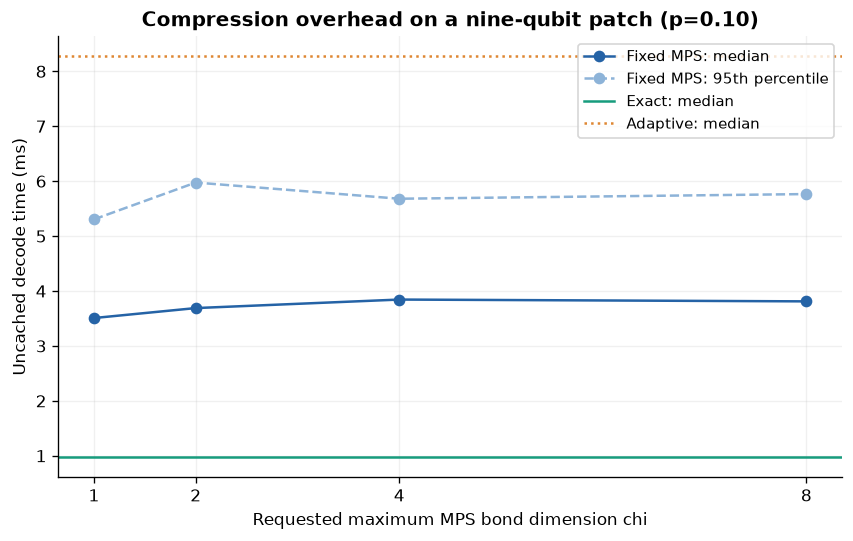

In [10]:
selected_p = .10
selected_rows = {r["method"]: r for r in report["records"] if np.isclose(r["p"], selected_p)}
table = ["| Decoder | Failure count | Failure estimate [95% CI] | Population failure | Median / p95 ms | Residual I / X / Y / Z counts |",
         "|---|---:|---|---:|---:|---|"]
for name, row in selected_rows.items():
    lo, hi = row["failure_95_ci"]
    table.append(f"| {name} | {row['failure_count']}/{row['trials']} | {row['logical_failure_rate']:.4f} [{lo:.4f}, {hi:.4f}] | "
                 f"{row['population_logical_failure_rate']:.6f} | {row['median_decode_ms']:.3f} / {row['p95_decode_ms']:.3f} | {row['residual_counts_IXYZ']} |")
display(Markdown("At **p=0.10**:\n\n" + "\n".join(table)))
fig = save(runtime_figure(report, selected_p), FIGURES / "runtime_vs_chi.png")
display(fig)
plt.close(fig)

**Why this graph matters:** compression is useful only if its cost and lost
information are acceptable. The cap is not the actual retained dimension; the
diagnostics below show which dimensions were used. On a width-three patch, full
boundary ranks can already be small, and QR/SVD overhead can outweigh any saved
contraction work. Exact contraction is not deliberately slowed down. Runtime is
reported separately from fidelity; there is no composite speed/fidelity score.

| Decoder | Actual retained dimensions | Final requested chi histogram (256 syndromes) | Max posterior error | Retries / exact fallbacks |
|---|---|---|---:|---:|
| exact | [] | {'None': 256} | 0 | 0 / 0 |
| chi1 | [1] | {'1': 256} | 0.987 | 0 / 0 |
| chi2 | [2] | {'2': 256} | 0.0986 | 0 / 0 |
| chi4 | [2, 4] | {'4': 256} | 1.48e-13 | 0 / 0 |
| chi8 | [2, 4] | {'8': 256} | 1.48e-13 | 0 / 0 |
| adaptive | [2, 4] | {'2': 64, '4': 192} | 2.02e-06 | 256 / 0 |
| chi2_column | [2] | {'2': 256} | 0.162 | 0 / 0 |
| equal_XZ_decoder | [] | {'None': 256} | 0 | 0 / 0 |

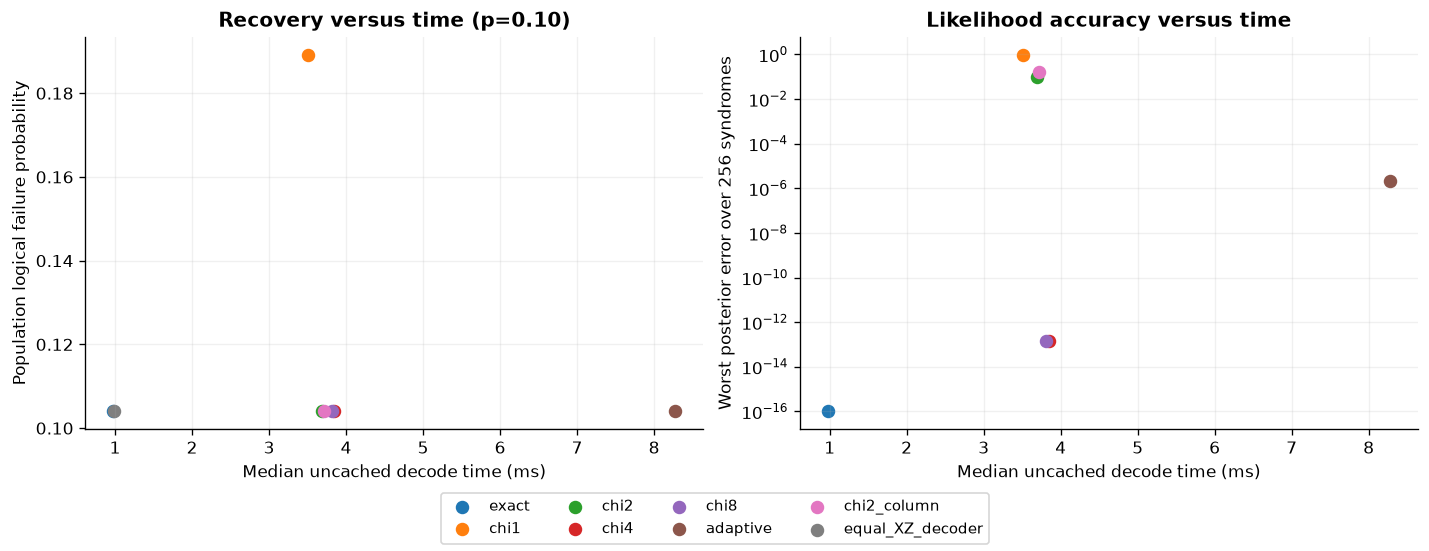

In [11]:
table = ["| Decoder | Actual retained dimensions | Final requested chi histogram (256 syndromes) | Max posterior error | Retries / exact fallbacks |",
         "|---|---|---|---:|---:|"]
for name, row in selected_rows.items():
    table.append(f"| {name} | {row['retained_bond_dimensions']} | {row['final_chi_histogram_over_256_syndromes']} | "
                 f"{row['posterior_max_absolute_error_vs_assumed_exact']:.3g} | {row['refined_syndromes']} / {row['exact_safety_fallback_syndromes']} |")
display(Markdown("\n".join(table)))
fig = save(tradeoff_figure(report, selected_p), FIGURES / "accuracy_runtime.png")
display(fig)
plt.close(fig)

**Why this graph matters:** the left panel compares actual recovery and computation
time. The right panel compares posterior accuracy and time, separately. A decoder
can perturb the likelihoods yet choose the same best recovery, so those are two
different notions of accuracy. The equal-X/Z decoder uses a different assumed
model and is omitted from the right panel. Its reported zero approximation error
means it contracts its *own assumed model* exactly, not that its posterior matches
the actual biased model. Zero errors on the logarithmic axis are plotted at
$10^{-16}$. The complete data also contain class-choice disagreements and the
population excess failure; disagreements caused only by ties incur no excess risk.

## 8. Fidelity, findings, and limits

After a Pauli error and a syndrome-consistent Pauli correction, the encoded qubit
has a residual logical Pauli channel. For an ideal encoded half of a maximally
entangled pair, the four logical Paulis produce orthogonal Bell states. Therefore
the identity-residual probability is the **entanglement fidelity** $F_e$.
Our recovery fraction estimates it under these assumptions. For a trace-preserving
channel on one logical qubit, the uniform average over pure logical states is
$F_{\rm avg}=(2F_e+1)/3$. This is not a measured hardware state fidelity.

In [12]:
exact_row = selected_rows["exact"]
chi1_row = selected_rows["chi1"]
adaptive_row = selected_rows["adaptive"]
equal_row = selected_rows["equal_XZ_decoder"]
paired = next(r for r in report["paired_comparisons"]
              if np.isclose(r["p"], selected_p) and r["first"] == "equal_XZ_decoder")
max_bias_gain = max(r["population_excess_failure_vs_matched_exact"] for r in report["records"]
                   if r["method"] == "equal_XZ_decoder")
findings = f'''At **p={selected_p:.2f}**, exact decoding recovered **{exact_row['logical_recovery_rate']:.2%}**
of {TRIALS:,} sampled errors. Its logical failure estimate was **{exact_row['logical_failure_rate']:.2%}**
(95% Wilson interval **{exact_row['failure_95_ci'][0]:.2%}–{exact_row['failure_95_ci'][1]:.2%}**).
The population failure probability for the stated model was **{exact_row['population_logical_failure_rate']:.4%}**.

Requested chi=1 gave population failure **{chi1_row['population_logical_failure_rate']:.4%}**;
adaptive contraction gave **{adaptive_row['population_logical_failure_rate']:.4%}**.
Exact decoding took median **{exact_row['median_decode_ms']:.3f} ms**, compared with
**{adaptive_row['median_decode_ms']:.3f} ms** for adaptive decoding. These measured
times include the extra adaptive attempts.

The largest population advantage of the matched decoder over the equal-X/Z
decoder across the tested p values was **{max_bias_gain:.6g}** in absolute failure
probability. At p=0.10 their paired sampled difference (equal-X/Z minus matched)
was **{paired['delta_failure_rate']:.6f}**, with conservative paired 95% interval
**[{paired['paired_conservative_95_ci'][0]:.6f}, {paired['paired_conservative_95_ci'][1]:.6f}]**. A zero or tiny difference is a result of
this code and sweep; it does not establish that noise-model knowledge is generally
irrelevant.

Here the estimated entanglement fidelity is **{exact_row['entanglement_fidelity_estimate']:.6f}**;
the corresponding average logical-state fidelity is
**{exact_row['average_logical_state_fidelity_estimate']:.6f}**, under the Pauli-channel assumptions above.
'''
display(Markdown(findings))
(RESULTS / "findings.md").write_text(findings, encoding="utf-8")
print("Saved outputs:")
for file in sorted(RESULTS.rglob("*")):
    if file.is_file():
        print(file.relative_to(ROOT))

At **p=0.10**, exact decoding recovered **89.74%**
of 10,000 sampled errors. Its logical failure estimate was **10.26%**
(95% Wilson interval **9.68%–10.87%**).
The population failure probability for the stated model was **10.4007%**.

Requested chi=1 gave population failure **18.9234%**;
adaptive contraction gave **10.4007%**.
Exact decoding took median **0.979 ms**, compared with
**8.275 ms** for adaptive decoding. These measured
times include the extra adaptive attempts.

The largest population advantage of the matched decoder over the equal-X/Z
decoder across the tested p values was **2.54647e-07** in absolute failure
probability. At p=0.10 their paired sampled difference (equal-X/Z minus matched)
was **0.000000**, with conservative paired 95% interval
**[-0.000438, 0.000438]**. A zero or tiny difference is a result of
this code and sweep; it does not establish that noise-model knowledge is generally
irrelevant.

Here the estimated entanglement fidelity is **0.897400**;
the corresponding average logical-state fidelity is
**0.931600**, under the Pauli-channel assumptions above.


Saved outputs:
results\adaptive_example.json
results\code_validation.json
results\exact_reference_validation.json
results\figures\accuracy_runtime.png
results\figures\class_posterior.png
results\figures\logical_failure_vs_p.png
results\figures\patch_and_syndrome.png
results\figures\runtime_vs_chi.png
results\findings.md
results\main\contraction_diagnostics.jsonl.gz
results\main\results.json
results\main\samples_and_weights.npz
results\smoke\contraction_diagnostics.jsonl.gz
results\smoke\results.json
results\smoke\samples_and_weights.npz
results\test_results.txt
results\worked_example.json


**Limitations.** This is one nine-data-qubit code with one round of perfect syndrome
information. There is no erasure flag, circuit noise, repeated noisy measurement,
leakage, correlated error channel, or hardware run. The implementation fixes the
patch geometry to distance three. Larger-distance scaling is not demonstrated.
The largest useful MPS rank is small here, so this is a correctness and truncation
study, not a claim of quantum advantage or contraction speedup. Floating-point
tie breaking can select different equally likely logical classes. Rare-class
posteriors can be sensitive even when an adaptive discarded-weight target passes.
The original event statement still needs organizer confirmation.

**Saved evidence.** `results/main/results.json` contains configuration, versions,
all summary statistics, intervals, and paired comparisons.
`samples_and_weights.npz` stores the actual errors, syndrome IDs, all raw class
weights, selected classes, residuals, and uncached timing samples. Method order and
p order are in the JSON. `contraction_diagnostics.jsonl.gz` records every SVD
spectrum, retained dimension, discarded norm, and adaptive attempt for all 256
syndromes at each p/method. Figures, code/reference validation, the worked example,
and test output are saved alongside this executed notebook.

**Sources and attribution.** The likelihood formulation and boundary-MPS approach
are informed by [Bravyi, Suchara & Vargo (2014)](https://arxiv.org/abs/1405.4883).
The fused local square-grid tensors and small-patch implementation here are written
for this submission; no existing surface-code decoder is called. Qiskit usage is
checked against the [official Pauli API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Pauli).